In [1]:
from src.data import load_splits

ds = load_splits()
print(ds)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
        num_rows: 25380
    })
    validation: Dataset({
        features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
        num_rows: 24844
    })
})


What is the data we actually collect ? An audio signal of course.

This audio signal can be described simply by:
- a sampling rate (how many numerical measures do you take per seconds)
- a data type: the format in which the measures are made (8 bits, 16 bits...)
- a list of bytes that represent our signal

From these information, we are able to fully represent our measured audio signal.

These informations are described in the `.metadata`attribute of an audio object.

In [2]:
import numpy as np

ex = ds['train'][np.random.randint(len(ds["train"]))]
print(ex['audio'].metadata)

AudioStreamMetadata:
  duration_seconds_from_header: 3.468375
  begin_stream_seconds_from_header: 0
  bit_rate: 0
  codec: flac
  stream_index: 0
  media_type: audio
  sample_rate: 16000
  num_channels: 1
  sample_format: s16
  duration_seconds: 3.468375
  begin_stream_seconds: 0



> Well, this wasn't entirely true. One thing worth to precise is that the signal is **compressed**, in order to be stored without taking much space in the disk, which is, quite obvious to do actually.

The compression algorithm used is defined in these metadata: `codec: flac`

In order to be processed, the audio has to be decoded, with a decoder.
As you can see, in this dataset, the codec is FLAC (Free Lossless Audio Codec).

In [ ]:
decoded = ex['audio'].get_all_samples()

print(decoded.data[0, 10000:10010]) # This is the decoded sequence between 10000 and 10010 th bytes

tensor([0.1274, 0.1395, 0.1545, 0.1620, 0.1508, 0.1341, 0.1149, 0.0770, 0.0343,
        0.0088])


> Notice that the output is a torch tensor. This is because `get_all_samples()` uses torchcodec, to decode the signal, which outputs a torch tensor.

Now that we got our signal, we can use it for various tasks. Two important ones for us:
- Reading the audio (for the data vizualisation)
- Transforming the signal (going to the frequency space)

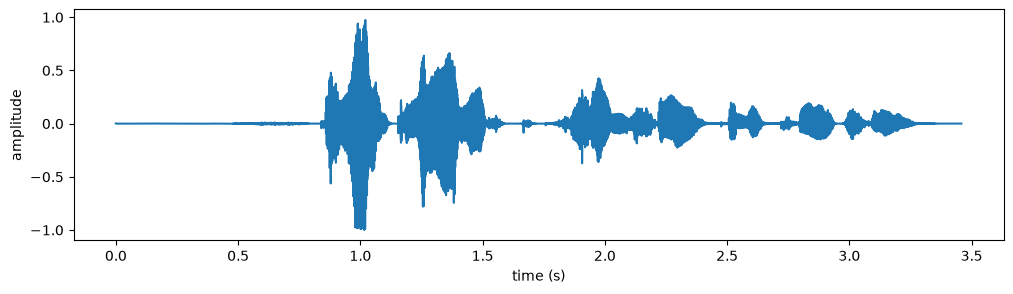

In [21]:
import torch
import matplotlib.pyplot as plt

from IPython.display import Audio

sr = 16000  # sampling rate (16 kHz as we saw in the metadata)
x = ds["train"][0]["audio"].get_all_samples().data[0]   # decoded 1D tensor
t = torch.arange(len(x)) / sr                           # We get the time of each sample

plt.figure(figsize=(12, 3))
plt.plot(t, x)
plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.show()

Audio(x.numpy(), rate=sr)                              # listen

Great, we are now able to display and read the signals. Now let's understand how can we easily transform them using PyTorch.

The first transform is the well known FFT (Fast Fourier Transform).

> Reminder: the fourier transform map our signal from the time space to the frequency space. Therefore it tells you how much each of frequency the signal contains.

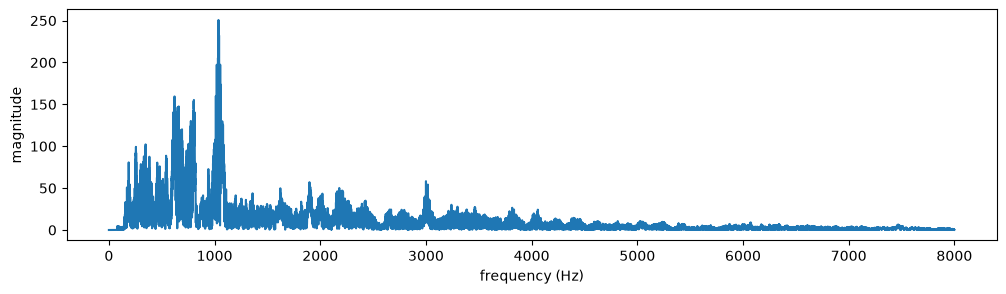

In [5]:
X = torch.fft.rfft(x)                           # Apply fft to our time signal
freqs = torch.fft.rfftfreq(len(x), d=1/sr)      # Rather than time, we need freqs

plt.figure(figsize=(12, 3))
plt.plot(freqs, X.abs())                             # magnitude = "how much"
plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")
plt.show()

torch.Size([257, 346])


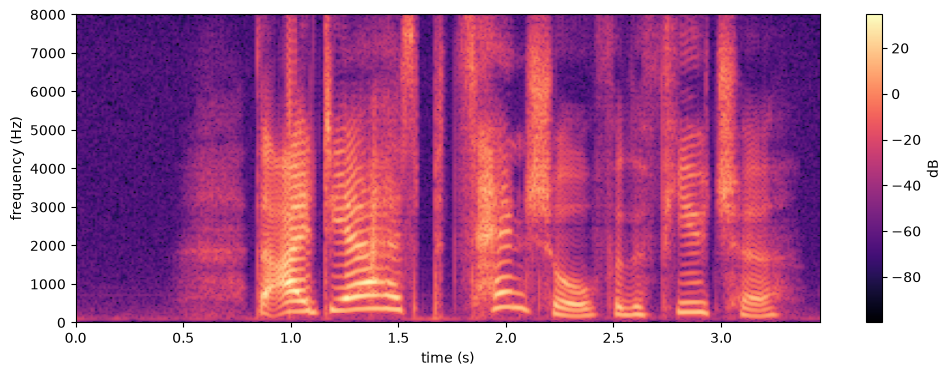

In [6]:
S = torch.stft(
    x,
    n_fft=512,                       # FFT size → 512/2 + 1 = 257 frequency bins
    hop_length=160,                  # step between windows: 160 samples = 10 ms
    win_length=400,                  # window length: 400 samples = 25 ms
    window=torch.hann_window(400),   # smooth the window edges (avoids artifacts)
    return_complex=True, 
)
print(S.shape)                       # torch.Size([257, 346]) = [frequencies, time frames]

S_db = 10 * torch.log10(S.abs() ** 2 + 1e-10)   # power in decibels (log scale)

plt.figure(figsize=(12, 4))
plt.imshow(S_db, origin="lower", aspect="auto", cmap="magma",
           extent=[0, len(x) / sr, 0, sr / 2])
plt.xlabel("time (s)"); plt.ylabel("frequency (Hz)"); plt.colorbar(label="dB")
plt.show()
